In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

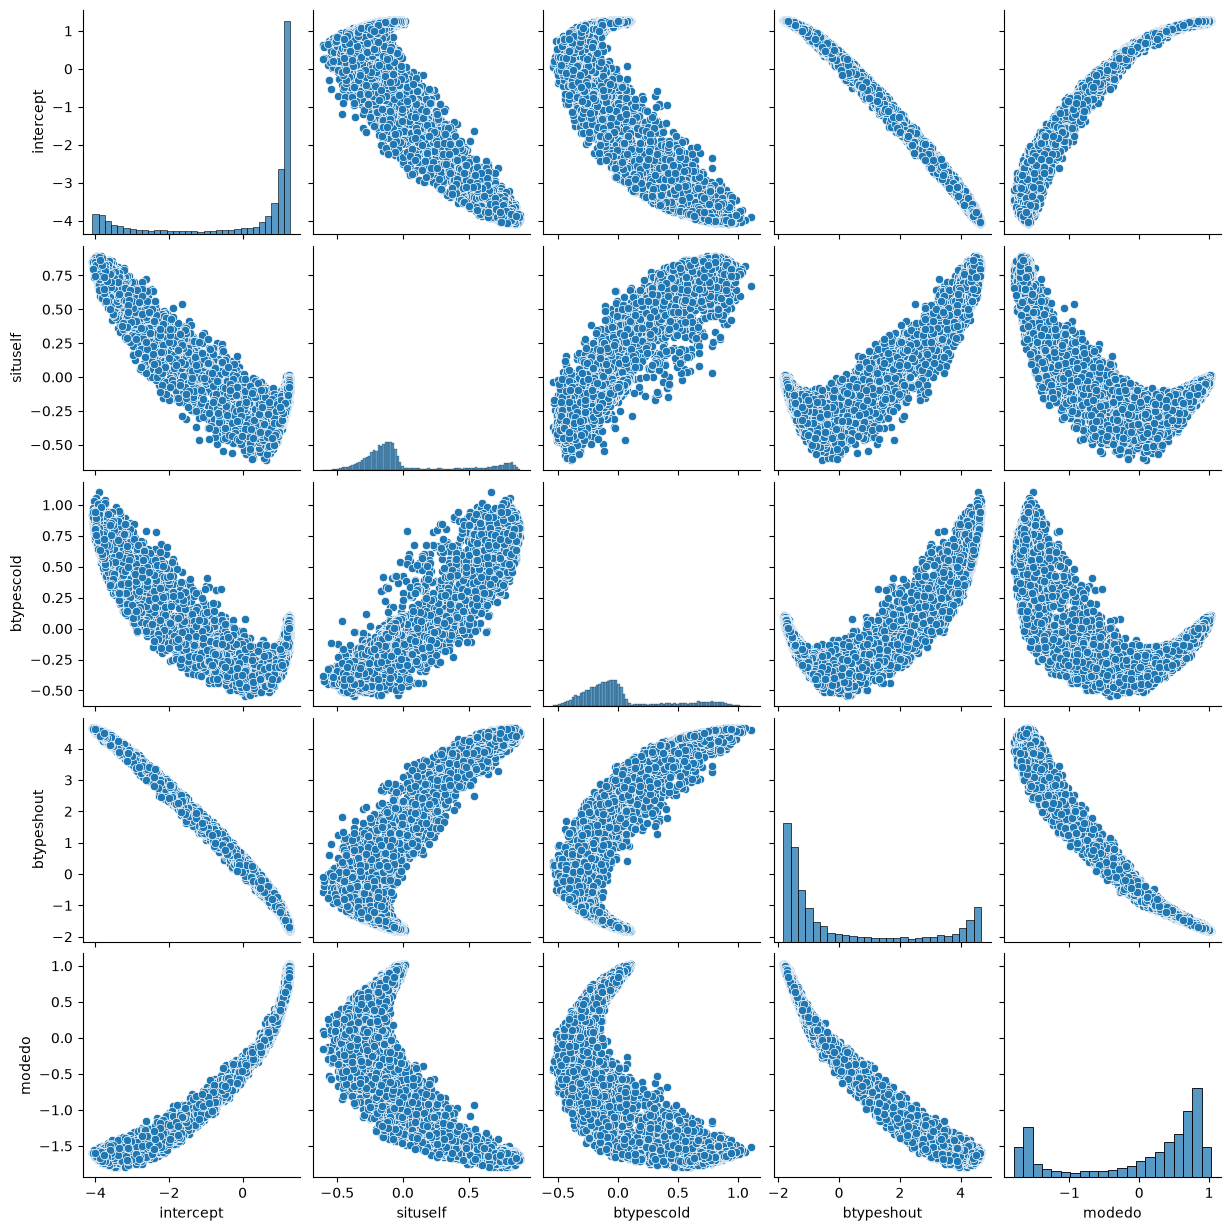

In [16]:
# Load generated random coefficients
generated = np.load("../save/VerbAgg/IWRCL/M100/seed42/generated.npy")

# Center random effects
generated = generated - generated.mean(axis=0)

# Convert to DataFrame
columns = [
    "intercept",
    "situself",
    "btypescold",
    "btypeshout",
    "modedo",
]
generated = pd.DataFrame(generated, columns=columns)

# Pair plot
sns.pairplot(generated)
plt.show()

In [28]:
# Load data
generated = np.load("../save/VerbAgg/IWRCL/M100/seed42/generated.npy")
u_prior = torch.from_numpy(generated).float()  # (M, 5)

df = pd.read_csv("../data/VerbAgg.csv", index_col=0)
data = torch.from_numpy(df.values).float()

w = data[:, :5]  # (N, 5)
y = data[:, 5]   # (N,)

with torch.inference_mode():
    # Posterior mean of random coefficients
    logits_prior = torch.sum(
        w[:, None, :] * u_prior[None, :, :],
        dim=-1,
    )  # (N, M)

    log_likelihood_prior = (
        y[:, None] * F.logsigmoid(logits_prior)
        + (1 - y[:, None]) * F.logsigmoid(-logits_prior)
    )

    weights = torch.softmax(log_likelihood_prior, dim=1)

    u_post = torch.sum(
        weights[:, :, None] * u_prior[None, :, :],
        dim=1,
    )  # (N, 5)

    # Fitted linear predictor
    linear = torch.sum(w * u_post, dim=1)

    # Negative log-likelihood
    nll = F.binary_cross_entropy_with_logits(
        linear,
        y,
        reduction="sum",
    ).item()

    # Fitted probabilities
    prob = torch.sigmoid(linear)
    eps = torch.finfo(prob.dtype).eps
    prob = prob.clamp(min=eps, max=1 - eps)

    # Sum of squared Pearson residuals
    p_resid = torch.sum(
        (y - prob) ** 2 / (prob * (1 - prob))
    ).item()

    # Sum of squared deviance residuals
    log_likelihood = (
        y * F.logsigmoid(linear)
        + (1 - y) * F.logsigmoid(-linear)
    )

    d_resid = (-2 * log_likelihood).sum().item()

print(f"NLL: {nll:.4f}")
print(f"Pearson: {p_resid:.4f}")
print(f"Deviance: {d_resid:.4f}")

NLL: 2600.0601
Pearson: 3781.0583
Deviance: 5200.1201
